# --------------------------------------------------------------
# Code for pendulum on a cart: MS-DeepONet architecture
# --------------------------------------------------------------
## This notebook includes:
 - Input signal generation (swing up trajectories)
 - Simulation of pendulum on a cart and data generation  
 - MS-DeepONet prediction model learning using pytorch
 - Model Predictive Control (MPC) simulation using CasADi
# --------------------------------------------------------------

In [47]:
# Standard libraries
import time
import itertools
import sys

# Scientific computing
import numpy as np
import pandas as pd
from scipy.integrate import solve_ivp
from scipy.io import savemat

# Plotting
import matplotlib.pyplot as plt

# Deep learning
import torch
import torch.nn.functional as F
import models  # your custom model module
import random


# Optimization (solving the MPC problem)
import casadi as ca

# Functions used in scripts
from functions import four_tank, NN, multisine, penulum_cart, Hankel_pendulum

### Generate input and output signals used for model learning (closed-loop data generation)

0/20001
1/20001
2/20001
3/20001
4/20001
5/20001
6/20001
7/20001
8/20001
9/20001
10/20001
11/20001
12/20001
13/20001
14/20001
15/20001
16/20001
17/20001
18/20001
19/20001
20/20001
21/20001
22/20001
23/20001
24/20001
25/20001
26/20001
27/20001
28/20001
29/20001
30/20001
31/20001
32/20001
33/20001
34/20001
35/20001
36/20001
37/20001
38/20001
39/20001
40/20001
41/20001
42/20001
43/20001
44/20001
45/20001
46/20001
47/20001
48/20001
49/20001
50/20001
51/20001
52/20001
53/20001
54/20001
55/20001
56/20001
57/20001
58/20001
59/20001
60/20001
61/20001
62/20001
63/20001
64/20001
65/20001
66/20001
67/20001
68/20001
69/20001
70/20001
71/20001
72/20001
73/20001
74/20001
75/20001
76/20001
77/20001
78/20001
79/20001
80/20001
81/20001
82/20001
83/20001
84/20001
85/20001
86/20001
87/20001
88/20001
89/20001
90/20001
91/20001
92/20001
93/20001
94/20001
95/20001
96/20001
97/20001
98/20001
99/20001
100/20001
101/20001
102/20001
103/20001
104/20001
105/20001
106/20001
107/20001
108/20001
109/20001
110/20001


Text(0.5, 0, 'Time [s]')

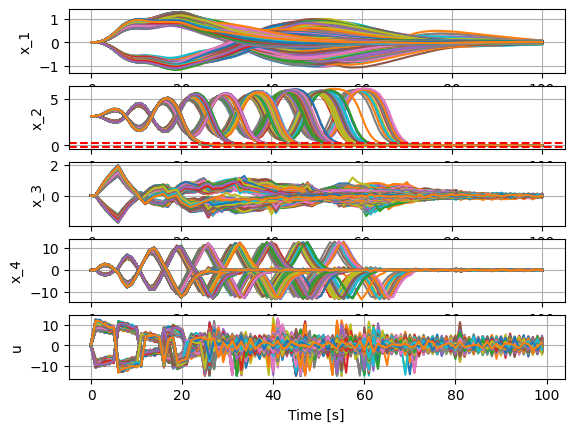

In [48]:
# Initialze empty data matrices
X_all = [] # State data matrix
U_all = [] # Input data matrix
K_su = np.linspace(0,4,20001) # Sweep over control parameters to get different swing ups# np.linspace(0,4,20001)

# Pendulum on a cart parameters
M = 2.4 # cart mass
m = 0.23 # pendulum mass
l = 0.18 # pendulum length
g = 9.81 # gravitational acceleration
Ts = 0.1 # Sampling time of the controller
N = 40 # Prediction horizon of the controller

params = {'M': M, 'm': m, 'l': l, 'g': g}

for j in range (0,len(K_su)):
    print(f'{j}/{len(K_su)}')
    k_su = K_su[j]
    k_cw = 2.25
    k_vw = 5
    k_em = 6
    eta = 1.05

    # Stabilizing controller parameters
    k1 = -4.4721 
    k2 = -75.9573
    k3 = -7.1427
    k4 = -11.5948

    # System parameters

    xmax = 0.7
    vmax = 10

    x0 = [0,np.pi,0,0]
    x = [x0]
    t_vec = [0]
    u_vec = []
    k_sim = 100  # number of simulation steps

    Vd = m*g*l

    excitation = 0.5
    excitation_stab = 0.5

    for k in range(k_sim):
        V = 0.5*m*l**2*x0[3]**2 + m*g*l*np.cos(x0[1])

        if np.abs(x0[1]) < 0.1:
            u_c = -k1*x0[0] -k2*x0[1] -k3*x0[2] -k4*x0[3] + np.random.normal(0, excitation)
            if (k % 20) == 0:
                u_c += np.random.normal(0,1)
        else:
            if 1 - np.abs(x0[0])/(xmax*2) <= 0:
                print('warning')
                continue
            u_cw = -k_su * np.sign(x0[3] * np.cos(x0[1])) + k_cw * np.sign(x0[0]) * np.log(1 - np.abs(x0[0])/(xmax*2)) 
            u_vw = k_vw*np.sign(x0[2])* np.log(1 - np.abs(x0[2])/(vmax)) 
            u_em = k_em * (np.exp(np.abs(V - eta * Vd)) - 1) * np.sign(V - Vd) * np.sign(x0[3] * np.cos(x0[1])) 
            u_c = u_cw + u_vw + u_em + np.random.normal(0, excitation_stab)
            if k > 200:
                u_c += np.random.normal(0, 1)

        u_c = np.clip(u_c, -20, 20)
        
        sol = solve_ivp(lambda t, y: penulum_cart(t, y, u_c, params),[0, Ts], x0, method='RK45')
        x0 = sol.y[:, -1]
        x.append(x0)  # store state
        t_vec.append((k+1) * Ts)  # store time
        u_vec.append(u_c)


    x = np.array(x)
    u_vec = np.array(u_vec)

    if np.abs(x[-1,1]) < 0.01 and max(np.abs(u_vec)) < 15:
        X_all.append(x)    
        U_all.append(u_vec)

# Make figure
plt.subplot(5,1,1)
for i in range (0,len(X_all)):
    plt.plot(X_all[i][:,0])
plt.ylabel("x_1")
plt.grid(True)
plt.subplot(5,1,2)
for i in range (0,len(X_all)):
    plt.plot(X_all[i][:,1])
# plt.plot(t_vec,x[:,1])
plt.axhline(y=0.2, color='r', linestyle='--')
plt.axhline(y=-0.2, color='r', linestyle='--')
plt.ylabel("x_2")
plt.grid(True)
plt.subplot(5,1,3)
for i in range (0,len(X_all)):
    plt.plot(X_all[i][:,2])
# plt.plot(t_vec,x[:,2])
plt.ylabel("x_3")
plt.grid(True)
plt.subplot(5,1,4)
for i in range (0,len(X_all)):
    plt.plot(X_all[i][:,3])
plt.ylabel("x_4")
plt.grid(True)
plt.subplot(5,1,5)
for i in range (0,len(X_all)):
    plt.plot(U_all[i])
# plt.plot(u_vec)
plt.ylabel("u")
plt.grid(True)
plt.xlabel("Time [s]")



### Generate Hankel matrices used for model learning

In [49]:
X_train = []
U_train = []
X_val = []
U_val = []

# Randomly select trajectories for training and validation data sets
numbers = random.sample(range(0, len(X_all)), k=len(X_all)-1000)  # get 10 unique random ints from 0 to 185
print(numbers)

for i in range (0,len(X_all)):
    if i in numbers:
        X_val.append(X_all[i])
        U_val.append(U_all[i])
    else:
        X_train.append(X_all[i])
        U_train.append(U_all[i])

X_val = np.array(X_val)
U_val = np.array(U_val)

X_train = np.array(X_train)
U_train = np.array(U_train)

Hu_val, Hx_val, Hy_val  = Hankel_pendulum(U_val,X_val,N)
Hu_train, Hx_train, Hy_train  = Hankel_pendulum(U_train,X_train,N)

print(f'Hu_val.shape = {Hu_val.shape}')
print(f'Hx_val.shape = {Hx_val.shape}')
print(f'Hy_val.shape = {Hy_val.shape}')

print(f'Hu_train.shape = {Hu_train.shape}')
print(f'Hx_train.shape = {Hx_train.shape}')
print(f'Hy_train.shape = {Hy_train.shape}')


# Example arrays (replace these with yours)

# Put them in a dictionary with variable names
data_to_save = {
    "X_val": X_val,
    "U_val": U_val,
    'Hu_val': Hu_val,
    'Hy_val': Hy_val,
    'Hx_val': Hx_val,
    "X_train": X_train,
    "U_train": U_train,
    'Hu_train': Hu_train,
    'Hy_train': Hy_train,
    'Hx_train': Hx_train
}

# Save to a .mat file
savemat('my_arrays.mat', data_to_save)
print("Arrays saved to 'my_arrays.mat'")

[845, 663, 734, 558, 231, 853, 1084, 560, 964, 1074, 334, 171, 1046, 810, 939, 321, 71, 571, 973, 1003, 883, 849, 733, 1006, 521, 225, 271, 216, 522, 1035, 724, 999, 763, 929, 27, 363, 47, 26, 815, 960, 472, 85, 798, 254, 930, 831, 400, 788, 1115, 150, 337, 359, 447, 866, 450, 468, 408, 312, 882, 373, 1043, 791, 372, 121, 1107, 228, 131, 190, 743, 58, 17, 995, 623, 1128, 38, 303, 459, 1110, 1048, 1059, 584, 953, 94, 432, 273, 300, 963, 1127, 335, 671, 867, 336, 601, 568, 848, 869, 1036, 702, 471, 841, 608, 60, 1041, 1045, 115, 126, 277, 68, 642, 198, 607, 117, 64, 412, 812, 956, 1063, 904, 1102, 1019, 179, 1088, 819, 157, 24, 807, 417, 885, 766, 1068, 102, 30, 465, 490, 591, 635, 572, 501, 139, 76, 1004, 61]
k = 0 / 141
k = 1 / 141
k = 2 / 141
k = 3 / 141
k = 4 / 141
k = 5 / 141
k = 6 / 141
k = 7 / 141
k = 8 / 141
k = 9 / 141
k = 10 / 141
k = 11 / 141
k = 12 / 141
k = 13 / 141
k = 14 / 141
k = 15 / 141
k = 16 / 141
k = 17 / 141
k = 18 / 141
k = 19 / 141
k = 20 / 141
k = 21 / 141
k = 22

### Train the MS-DeepONet model 

In [50]:
# Define the network dimensions
ld_list = [40] # Neurons in output hidden layer 
neuron_b_list = [[128] + [256] + [128]] # Neurons in hidden layer Branch network (3 layers with 128, 256, 128 neurons respectively)
neuron_t_list = [[128] + [256] + [128]] # Neurons in hidden layer Trunk network (3 layers with 128, 256, 128 neurons respectively)
N_epoch = 4001 # Number of epochs used for training the model
N_comb_val = len(ld_list)*len(neuron_t_list)*len(neuron_t_list) # Total number of hyperparameter configurations to train for

# make sure that GPU is used when available
# device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
device = torch.device("cpu:0")
print("Using device:", device)

# Convert training data to tensors
trunk_input_train = torch.tensor(Hx_train, dtype=torch.float32).to(device).T
branch_input_train = torch.tensor(Hu_train, dtype=torch.float32).to(device).T
output_train = torch.squeeze(torch.tensor(Hy_train, dtype=torch.float32).to(device)).T

# Convert validation data to tensors
trunk_input_val = torch.tensor(Hx_val, dtype=torch.float32).to(device).T
branch_input_val = torch.tensor(Hu_val, dtype=torch.float32).to(device).T
output_val = torch.squeeze(torch.tensor(Hy_val, dtype=torch.float32).to(device)).T

# Network and data dimensions
B_train = len(trunk_input_train[:,0])
B_val = len(trunk_input_val[:,0])
nx = len(trunk_input_train[0,:])
Nnu = len(branch_input_train[0,:])
Nny = len(output_train[0,:])

# Define the training loop using pytorch 
def train(idx,neuron_b,neuron_t,ld,loss_val_i,niter,N_comb):
    # Define the Branch network:
    branch = models.MLP(
        layers=[Nnu] + neuron_b + [ld*Nny],
        activation=F.tanh,
    ).to(device)

    # Define the Trunk network:
    trunk = models.MLP(layers=[nx] + neuron_t + [ld], activation=F.tanh).to(device)

    # Define the optimizer, learning rate, weight decay
    optimizer = torch.optim.AdamW(
        list(branch.parameters()) + list(trunk.parameters()), 
        lr=1e-3,
        weight_decay=1e-5  # L2 regularization (weight decay)
    )

    # Add a learning rate scheduler that reduces the learning rate by a factor of gamma every step_size iterations
    scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=2000, gamma=0.1)

    # Initialize empty list for storing the training and validation loss
    train_loss_hist = []
    val_loss_hist = []
    t0 = time.time()
    # training loop
    for i in range(niter):
        # Training step
        def train_step():
            optimizer.zero_grad() # reset the gradients    
            # Forward pass:           
            b_out = branch(branch_input_train) # Branch net forward pass
            t_out = trunk(trunk_input_train) # Trunk net forward pass
            b_out = b_out.reshape(B_train, Nny, ld) # convert Branch net output layer into matrix
            u_pred = torch.einsum("bij,bj->bi", b_out, t_out) # Product layer
            loss = torch.mean((u_pred - output_train) ** 2) / torch.mean((output_train) ** 2) # Calculate training loss 
            # Backward pass
            loss.backward()
            # Update parameters
            optimizer.step()
            return loss
        
        # Validation step
        def validation_step():
             with torch.no_grad():               
                b_out = branch(branch_input_val)
                t_out = trunk(trunk_input_val)
                b_out = b_out.reshape(B_val, Nny, ld)
                u_pred = torch.einsum("bij,bj->bi", b_out, t_out)
                loss = torch.mean((u_pred - output_val) ** 2) / torch.mean((output_val) ** 2)
                return loss

        loss_train = train_step() # Perform a training step (includes forward pass, loss calc, backward pass, optimizer step)
        loss_val = validation_step() # Perform a validation step (forward pass + loss calc, no weight updates)
        l_train = loss_train.detach().cpu().numpy() # Move training loss tensor to CPU, detach from graph, convert to NumPy
        l_val = loss_val.detach().cpu().numpy() # Same as above for validation loss

        train_loss_hist.append(l_train) # Append training loss data 
        val_loss_hist.append(l_val) # Append validation loss data 

        # Get the current learning rate from the optimizer
        current_lr = optimizer.param_groups[0]['lr'] # Get the current learning rate from the optimizer
        current_lr = round(current_lr, 5) # Round the learning rate to 5 decimal places for printing
        
         # Print usefull information during training:
        if i % 10 == 0:
            print(
                "index: ",
                idx,
                "/ ",
                N_comb,
                " Epoch: ",
                i + 1,
                "Learning rate: ",
                current_lr,
                "Train loss",
                l_train,
                "Val loss",
                l_val,
                flush=True,
            )

        # Save the model every 10 iterations and only when validation loss has decreased
        if i % 10 == 0 and loss_val_i >= l_val:
            loss_val_i = l_val
            l_indx_i = i
            torch.save(branch, "data_MS/kan_mlp_branch_idx_{}".format(str(int(idx))))
            torch.save(trunk, "data_MS/kan_mlp_trunk_idx_{}".format(str(int(idx))))

        # Step the scheduler at the end of each iteration
        scheduler.step()

    t1 = time.time()
    print("Total time: ", t1 - t0, flush=True)
    t_elapsed = t1 - t0
        
    # Save training and validation losses
    np.save("data_MS/train_loss.npy", train_loss_hist, allow_pickle=True)
    np.save("data_MS/val_loss.npy", val_loss_hist, allow_pickle=True)

    return np.array(train_loss_hist), np.array(val_loss_hist), l_indx_i, loss_val_i, t_elapsed 


# start of the ablation study 
ablation_results = [] # Initialize empty list for storing the ablation results 
combinations = itertools.product(ld_list,neuron_b_list,neuron_t_list)  # Generate set of hyperparameter configurations for ablation study 
idx_i = 0 # Initialize training index 

# Looping through the range of indices (1 to idx_total-1 in this case, but you can extend it)
for ld_i, neuron_b_i, neuron_t_i in combinations:
    idx_i += 1
    # Call the train function with the current index
    train_loss_hist_i, val_loss_hist_i, l_indx_opt, loss_val_opt, t_elapsed =  train(idx=idx_i, neuron_b = neuron_b_i ,neuron_t =neuron_t_i,ld=ld_i, loss_val_i=float('inf'),niter=N_epoch,N_comb = N_comb_val)
    
    # Create a dictionary to store the results
    results = {
        'idx': idx_i,
        'neurons output layer': ld_i,
        'neurons hidden per layer branch': neuron_b_i,
        'neurons hidden per layer trunk': neuron_t_i,
        'training loss': train_loss_hist_i,
        'validation loss': val_loss_hist_i,
        'training time': t_elapsed
    }
    
    # Append the results to the ablation_results list
    ablation_results.append(results)


Using device: cpu:0
index:  1 /  1  Epoch:  1 Learning rate:  0.001 Train loss 1.0022417 Val loss 0.98832667
index:  1 /  1  Epoch:  11 Learning rate:  0.001 Train loss 0.6285784 Val loss 0.60907745
index:  1 /  1  Epoch:  21 Learning rate:  0.001 Train loss 0.43220094 Val loss 0.43565568
index:  1 /  1  Epoch:  31 Learning rate:  0.001 Train loss 0.31790277 Val loss 0.327405
index:  1 /  1  Epoch:  41 Learning rate:  0.001 Train loss 0.22578387 Val loss 0.24032521
index:  1 /  1  Epoch:  51 Learning rate:  0.001 Train loss 0.17521515 Val loss 0.19063759
index:  1 /  1  Epoch:  61 Learning rate:  0.001 Train loss 0.14252794 Val loss 0.15838924
index:  1 /  1  Epoch:  71 Learning rate:  0.001 Train loss 0.12033317 Val loss 0.13552593
index:  1 /  1  Epoch:  81 Learning rate:  0.001 Train loss 0.10401524 Val loss 0.11824442
index:  1 /  1  Epoch:  91 Learning rate:  0.001 Train loss 0.09178296 Val loss 0.105370685
index:  1 /  1  Epoch:  101 Learning rate:  0.001 Train loss 0.082287036 V

### Convert the ablation results to a .mat file for analysis with MATLAB

Text(0.5, 1.0, 'Training and validation loss')

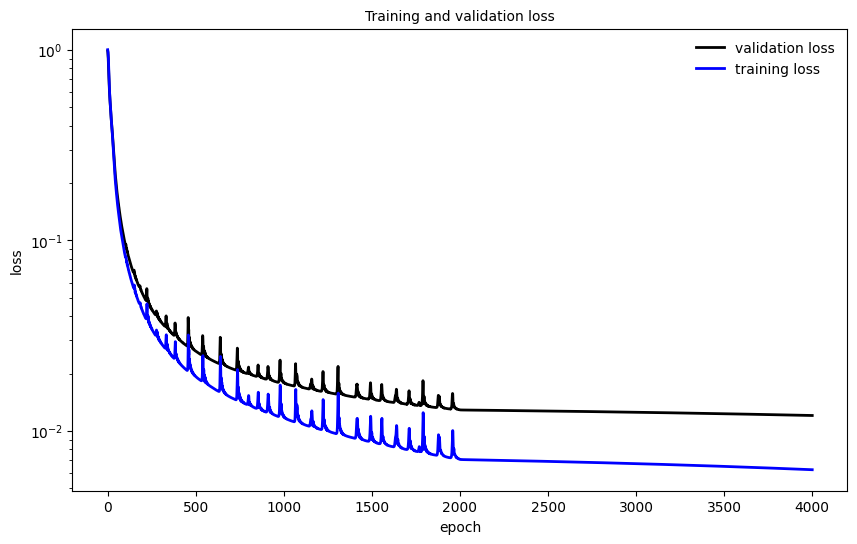

In [51]:
# Prepare dictionary for saving in .mat format
ablation_mat = {}

# Flatten the ablation_results list into a structured dict
for i, result in enumerate(ablation_results):
    ablation_mat[f'result_{i}'] = {
        'idx': result['idx'],
        'neurons_output_layer': result['neurons output layer'],
        'neurons_hidden_per_layer_branch': result['neurons hidden per layer branch'],
        'neurons_hidden_per_layer_trunk': result['neurons hidden per layer trunk'],
        'train_loss': np.array(result['training loss']),
        'val_loss': np.array(result['validation loss']),
        'T_train': np.array(result['training time'])
    }


# Save the structured dict to a .mat file
savemat("data_MS/ablation_results.mat", ablation_mat)

# Make figure
plt.figure(figsize=(10, 6))
for i in range(len(ablation_mat)):
    plt.subplot(len(ablation_mat), 1, i+1)
    plt.semilogy(ablation_mat[f'result_{i}']['val_loss'], '-k', lw=2.0, label="validation loss")
    plt.semilogy(ablation_mat[f'result_{i}']['train_loss'], '-b', lw=2.0, label="training loss")
    plt.xlabel('epoch')
    plt.ylabel('loss')
    plt.legend(frameon=False, loc = 'best')
    
plt.title('Training and validation loss', fontsize = 10)    


### Perform MS-DeepONet based MPC simulation

i = 0 / 100
x_current_ext = [ 0.5 -1.   0.   0.   0. ]
i = 1 / 100
x_current_ext = [ 0.48242002 -0.99749635  0.07071798 -0.35073487 -1.36282526]
i = 2 / 100
x_current_ext = [ 0.46768703 -0.99474918  0.10234289  0.05637595  0.7499551 ]
i = 3 / 100
x_current_ext = [ 4.76208035e-01 -9.99999734e-01  7.28758397e-04  1.12867189e-01
  1.21150313e+00]
i = 4 / 100
x_current_ext = [ 0.49008545 -0.99245775 -0.12258718  0.16320636  1.16995375]
i = 5 / 100
x_current_ext = [ 0.48859698 -0.99063622 -0.13652796 -0.19309516 -0.8983112 ]
i = 6 / 100
x_current_ext = [ 0.45676401 -0.99971066  0.02405416 -0.44173045 -2.20588713]
i = 7 / 100
x_current_ext = [ 0.4326459  -0.98954106  0.14425151 -0.03943523 -0.12397806]
i = 8 / 100
x_current_ext = [ 0.46976053 -0.99934074 -0.03630539  0.77992557  3.62171214]
i = 9 / 100
x_current_ext = [ 0.57203157 -0.89456448 -0.44693891  1.25753429  4.56938534]
i = 10 / 100
x_current_ext = [ 0.70440824 -0.6765509  -0.73639587  1.38983851  2.49991581]
i = 11 / 100
x_current_

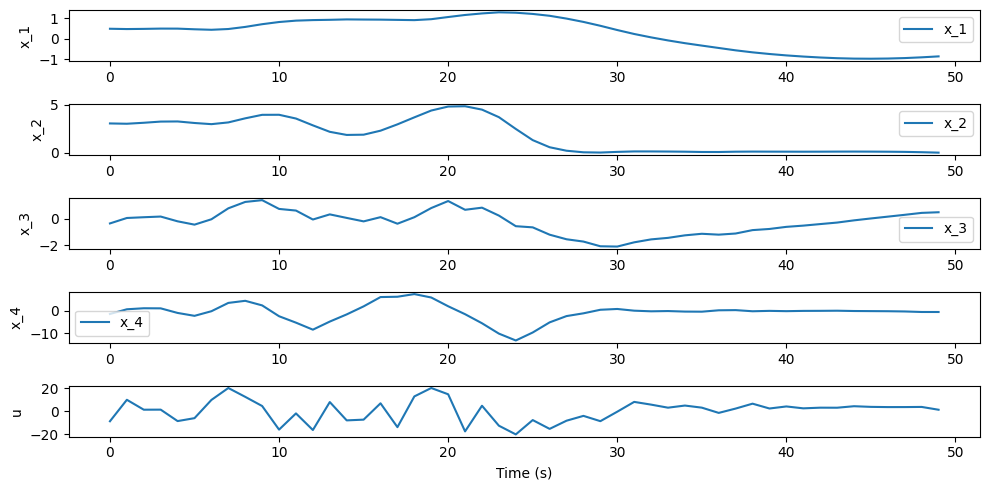

In [54]:
# select optimal index based on the minimal validation loss in ablation_results:
idx_opt = 1 # change to correct index as defined in the code block: Train the MS-DeepONet model 
branch = torch.load("data_MS/kan_mlp_branch_idx_{}".format(str(int(idx_opt))), map_location=torch.device('cpu'), weights_only=False)
trunk = torch.load("data_MS/kan_mlp_trunk_idx_{}".format(str(int(idx_opt))), map_location=torch.device('cpu'), weights_only=False)

# Network dimensions
ld = 40 # Select here correct number of neurons in output layer of model with index idx_opt
Nny = N*5
Ts = 0.1 # Sampling time of the controller
# Pendulum on a cart parameters
M = 2.4 # cart mass
m = 0.23 # pendulum mass
l = 0.18 # pendulum length
g = 9.81 # gravitational acceleration
Ts = 0.1 # Sampling time of the controller
N = 40 # Prediction horizon of the controller

params = {'M': M, 'm': m, 'l': l, 'g': g}

# System dimensions pendulum on a cart system (we extend the state by replacing theta with cos(theta) and sin(theta))
nx = 5  # [x, cos(theta), sin(theta), dx, dtheta]
ny = 5  # [x, cos(theta), sin(theta), dx, dtheta]
nu = 1  # torque

# MPC cost function matrices
Q = np.diag(np.tile([1, 1000, 1, 1, 1], N))
R = 0.01*np.eye(N * nu)

# Define reference signal
Ref = np.tile([0, 1, 0, 0, 0], N)

# Set up optimization problem
opti = ca.Opti()
y = opti.variable(ny*N,)
u = opti.variable(nu*N,)
du = opti.variable(nu*N,)
x0 = opti.parameter(nx)
u0 = opti.parameter(nu)

# sys.exit()
# Define cost function
cost = ca.mtimes([(y-Ref).T, Q, (y-Ref)]) + ca.mtimes([u.T, R, u])

# Neural network predictions
b_out = NN(u, branch, np.tanh)
t_out = NN(x0, trunk, np.tanh)
b_out = ca.reshape(b_out, ld,Nny)

# Define constrains for the MPC problem
opti.subject_to(y == b_out.T@t_out)
opti.subject_to(opti.bounded(-20.0, u, 20.0))
opti.minimize(cost)

# Solver options
opti.solver('ipopt', {'ipopt.print_level': 0, 'print_time': 0})

x_vals = [] # Initialize empty list for storing state data
u_vals = [] # Initialize empty list for storing input data
solve_times = []  # Initialize empty list to store time per control action 


x_current = np.array([0.5, np.pi, 0.0 ,0.0])  # state
x_current_ext = np.array([0.5, -1.0, 0.0 ,0.0, 0.0])  # extended state 
u_mpc = np.array([0]) # Initial condition for inut (needed for \delta u(0))

# Start of the simulation loop
for i in range(50):
    print(f'i = {i} / {100}')
    print(f'x_current_ext = {x_current_ext}')
    
    opti.set_value(x0, x_current_ext) # Set initial condition

    start = time.perf_counter() # initialize counter
    sol = opti.solve() # solve MPC problem
    elapsed = time.perf_counter() - start # store required time for solving MPC problem
    solve_times.append(elapsed)  # Store each solve time
    
    u_mpc = sol.value(u[0]) # Extract current input, to be applied to the system 
    
    # Apply input to pendulum on a cart and simulate for Ts seconds
    sol_ivp = solve_ivp(lambda t, y: penulum_cart(t, y, u_mpc, params),[0, Ts], x_current, method='RK45')

     # Take the last value as the new initial condition
    x_next = sol_ivp.y[:, -1] # measured state at t = (i+1)T_s
    x_vals.append(x_next) # Append state data vector
    u_vals.append(u_mpc) # Append input data vector
    x_current = x_next # Initialize new current state for next iteration 
    x_current_ext = np.array([x_next[0], np.cos(x_next[1]), np.sin(x_next[1]) ,x_next[2], x_next[3]])  # Initialize new current extended state for next iteration 

solve_times = np.array(solve_times) # Convert control times to numpy array 
x_vals = np.array(x_vals) # Convert state data to numpy array 
u_vals = np.array(u_vals) # Convert input data to numpy array 
t_vec = np.arange(100) * Ts # Define time vector

# Make figure of the closed--loop response
plt.figure(figsize=(10, 5))
for i in range(4):
    plt.subplot(5, 1, i+1)
    plt.plot( x_vals[:, i], label=f'x_{i+1}')
    plt.ylabel(f'x_{i+1}')
    plt.legend()
plt.subplot(5, 1, 5)
plt.plot(u_vals)
plt.ylabel('u')
plt.xlabel('Time (s)')
plt.tight_layout()
plt.show()

## save MPC results a .mat files for analysis in Matlab

In [53]:
# Put them in a dictionary with variable names
data_to_save = {
    "x_vals_MS": x_vals,
    "u_vals_MS": u_vals,
    "solve_times_MS": solve_times,
}

# Save to a .mat file
savemat('data_MS/MS_pendulum_on_cart.mat', data_to_save)
print("Arrays saved to 'MS_pendulum_on_cart.mat'")

Arrays saved to 'MS_pendulum_on_cart.mat'
